# Muon template KDEs and the SAY closure bias (step2, flavor)
`asimov_closure.ipynb` shows that the SAY likelihood stopped recovering the injected parameters when the HESE muon
template was replaced by the new combined conv/prompt template, while Poisson closes exactly in every case:

| muon template | component | astro_norm − injected | muon norm − 1 |
|---|---|---|---|
| combined conv+prompt (`main_muonconvpromptcombined.cfg`) | `muontemplate_combined_hese` | **+0.304** | **−0.303** |
| paper KDE (`..._paper.yaml`) | `muontemplate_hese` | +0.036 | −0.135 |
| non-paper KDE (`..._bdt1_0.333333_bdt2_0.366667.yaml`) | `muontemplate_hese` | +0.001 | −0.022 |

The only thing SAY uses and Poisson does not is the expected MC fluctuation $\sigma^2$ per bin
(`ssq`, `NNMFit/likelihoods/say_llh.py`). This notebook looks at the muon template KDEs themselves and at how much of
the HESE Tracks $\sigma^2$ they carry.

In [1]:
import os
import pickle
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.optimize import minimize
from scipy.special import gammaln

In [2]:
import sys
STEP2_DIR = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/unblind/step2_hese_flavor_reunblind"
sys.path.insert(0, STEP2_DIR)
from plot_configs import _CHAN_SPECS  # analysis binning per channel

plotting_path = f"{STEP2_DIR}/studies/plots_muon_template_kde"
os.makedirs(plotting_path, exist_ok=True)

# HESE Tracks, the only channel the muon templates are applied to:
# the other HESE det configs list them in `excluded_components` (IC86_pass2_SnowStorm_FTP_HESE_Cascades.cfg,
# IC86_pass2_SnowStorm_FTP_HESE_DoubleCascades.cfg)
DET_CONF = "IC86_pass2_SnowStorm_FTP_HESE_Tracks"
TRACKS_SPEC = dict(_CHAN_SPECS[1][2])

# override/livetime/hese_livetime_13yr_asr.cfg, the livetime of all asimov_closure scans except _oldlive
LIVETIME = 411785301.60  # s = 13.0576 yr

KDE_DIR = "/data/user/tvaneede/GlobalFit/reco_processing/NNMFit/notebooks/muons/KDE"
COMBINED_DIR = "/data/user/tvaneede/FlavorGlobalFit/muon_template_hese/kde"
template_files = {
    # Neha's KDE as it sits on /data/ana: the default template_file of muontemplate_hese in
    # components.yaml, not used in any asimov_closure scan
    "neha":           "/data/ana/Diffuse/GlobalFit_Flavor/NNMFit_Configs/override/MuonGun/Tracks_KDE.pickle",
    # the rebuild of that KDE (notebooks/muons/hese_muons_kde.ipynb), used through
    # override/muon/..._bdt1_0.333333_bdt2_0.366667.yaml by the `muonconvneha` closure scans
    "reproduce_neha": f"{KDE_DIR}/HESE_Tracks_KDE_11features_plus_rloglmilli_econf_evtgen_bdt1_0.333333_bdt2_0.366667.pickle",
    # muontemplate_hese, override/muon/..._paper.yaml (hese_muons_paper.ipynb)
    "paper":          f"{KDE_DIR}/HESE_Tracks_KDE_11features_plus_rloglmilli_econf_evtgen_bdt1_0.333333_bdt2_0.366667_paper.pickle",
    # the two templates of muontemplate_combined_hese (FlavorGlobalFit/muon_template_hese/)
    "conv":           f"{COMBINED_DIR}/MC-v8_weight-MuonWeightCombinedConv_scaling-9.66/muon_template_MC-v8_weight-MuonWeightCombinedConv_scaling-9.66.pickle",
    "prompt":         f"{COMBINED_DIR}/MC-v8_weight-MuonWeightCombinedPrompt_scaling-1.05/muon_template_MC-v8_weight-MuonWeightCombinedPrompt_scaling-1.05.pickle",
    # the same two rebuilt with template_fluctuation as a 1 sigma error and a seeded bootstrap (_sigma),
    # used by the _newmuon scans through override/muon/muontemplate_combined_hese_sigma.yaml
    "conv_sigma":     f"{COMBINED_DIR}/MC-v8_weight-MuonWeightCombinedConv_scaling-9.66_sigma/muon_template_MC-v8_weight-MuonWeightCombinedConv_scaling-9.66_sigma.pickle",
    "prompt_sigma":   f"{COMBINED_DIR}/MC-v8_weight-MuonWeightCombinedPrompt_scaling-1.05_sigma/muon_template_MC-v8_weight-MuonWeightCombinedPrompt_scaling-1.05_sigma.pickle",
}

# the templates to compare, and the closure bias of the four the asimov_closure scans used
# (NaN for `neha`, which no scan used; `combined_sigma` is the SAY_newmuon scan)
labels = {
    "neha":           "neha KDE (/data/ana)",
    "reproduce_neha": "non-paper KDE (rebuilt)",
    "paper":          "paper KDE",
    "combined":       "combined conv+prompt",
    "combined_sigma": "combined, corrected sigma",
}
colours = {"neha": "tab:red", "reproduce_neha": "tab:green", "paper": "tab:orange",
           "combined": "tab:blue", "combined_sigma": "tab:purple"}
closure_bias = pd.DataFrame(
    {"astro_norm - injected": {"neha": np.nan, "reproduce_neha": 0.0007,
                               "paper": 0.0361, "combined": 0.3035, "combined_sigma": 0.0804},
     "muon norm - 1":         {"neha": np.nan, "reproduce_neha": -0.0220,
                               "paper": -0.1349, "combined": -0.3026, "combined_sigma": -0.1004}}
)

In [3]:
import matplotlib.font_manager as font_manager
font_axis_label = {'family': 'serif',
        'color':  'black',
        'weight': 'normal',
        'size': 22,
        }
font_title = {'family': 'serif',
        'color':  'black',
        'weight': 'bold',
        'size': 20,
        }
font_legend = font_manager.FontProperties(family='serif',
                                   weight='normal',
                                   style='normal', size=13)

plt.rcParams["figure.figsize"] = (6,6)
plt.rcParams.update({'font.family':'serif'})

## The muon templates
A template pickle holds `template` (the expected rate per analysis bin, in Hz) and `template_fluctuation`
(the KDE error of that rate). NNMFit multiplies both by the livetime of the detector config; the expectation enters
`mu` and the fluctuation enters `ssq` squared (`core/histogram_builder.py`, `ssq += (hist_fluctuation * livetime)**2`),
so `template_fluctuation * livetime` is the $\sigma$ of the muon component in that bin.

Five templates are compared:

| key | file | used by |
|---|---|---|
| `neha` | `/data/ana/Diffuse/GlobalFit_Flavor/NNMFit_Configs/override/MuonGun/Tracks_KDE.pickle` | the default `template_file` of `muontemplate_hese` in `components.yaml`; no `asimov_closure` scan uses it |
| `reproduce_neha` | `notebooks/muons/KDE/HESE_Tracks_KDE_..._bdt1_0.333333_bdt2_0.366667.pickle` | `override/muon/..._bdt1_0.333333_bdt2_0.366667.yaml`, i.e. the `muonconvneha` scans |
| `paper` | the same with `_paper` | `override/muon/..._paper.yaml` |
| `conv`, `prompt` | `FlavorGlobalFit/muon_template_hese/kde/MC-v8_...` | the two inputs of `muontemplate_combined_hese`, as the first closure scans used them |
| `conv_sigma`, `prompt_sigma` | the same two with the `_sigma` suffix | the corrected rebuild, used by the `_newmuon` scans through `override/muon/muontemplate_combined_hese_sigma.yaml` |

`reproduce_neha` is our rebuild of the `neha` KDE (`notebooks/muons/hese_muons_kde.ipynb`), so the first two rows
should be the same template — they are not. The `/data/ana` one holds 1.77 muon events in 13 yr against 0.37, a
factor 4.8 in rate, and its $\sum\sigma^2$ is 71x larger. Its `description` field is the unfilled placeholder
`"KDE for MuonGun generated using ####"`, so what went into it is not recorded in the pickle. Only the rebuild was
ever used in a fit here, but the `/data/ana` file is what any configuration that does not override
`muontemplate_hese` picks up, so it is worth keeping in the comparison.

`muontemplate_combined_hese` is a `CombinedTemplateFlux`: it combines the conv and prompt templates as
$\mu = N\,[(1+a)\,T_1 + (1-a)\,T_2]$ with $\sigma = N\,\sqrt{((1+a)f_1)^2 + ((1-a)f_2)^2}$, and both input templates
hold half the total rate by construction. Below they are combined at the injected point
`combined_muongun_norm = 1`, `muongun_asymmetry = 0`, i.e. $T_1 + T_2$ and $\sqrt{f_1^2 + f_2^2}$.

In [4]:
raw = {name: pickle.load(open(path, "rb")) for name, path in template_files.items()}

# binning of the templates must be the analysis binning (TemplateFlux asserts this at fit time)
for name, d in raw.items():
    np.testing.assert_allclose(d["energy_bins"], TRACKS_SPEC["binning"]["reco_energy"])
    np.testing.assert_allclose(d["zenith_bins"], TRACKS_SPEC["binning"]["reco_zenith"], atol=1e-13)
energy_bins = TRACKS_SPEC["binning"]["reco_energy"]
zenith_bins = TRACKS_SPEC["binning"]["reco_zenith"]
n_e, n_z = len(energy_bins) - 1, len(zenith_bins) - 1

# the two CombinedTemplateFlux pairs: the template of the first closure scans and the corrected-sigma rebuild
combined_pairs = {"combined": ("conv", "prompt"), "combined_sigma": ("conv_sigma", "prompt_sigma")}

# CombinedTemplateFlux warns if the two input templates are not normalised to the same rate
for name, (key_conv, key_prompt) in combined_pairs.items():
    sum_conv, sum_prompt = raw[key_conv]["template"].sum(), raw[key_prompt]["template"].sum()
    print(f"{labels[name]} inputs: conv {sum_conv:.6e} Hz, prompt {sum_prompt:.6e} Hz, "
          f"ratio {sum_conv / sum_prompt:.6f} (CombinedTemplateFlux requires 1 within 1%)")

# mu and sigma per bin in events, as NNMFit builds them at norm = 1 (asymmetry = 0 for the combined template)
mu, sigma = {}, {}
for name in ["neha", "reproduce_neha", "paper"]:
    mu[name] = raw[name]["template"] * LIVETIME
    sigma[name] = raw[name]["template_fluctuation"] * LIVETIME
for name, (key_conv, key_prompt) in combined_pairs.items():
    mu[name] = (raw[key_conv]["template"] + raw[key_prompt]["template"]) * LIVETIME
    sigma[name] = np.sqrt(raw[key_conv]["template_fluctuation"]**2
                          + raw[key_prompt]["template_fluctuation"]**2) * LIVETIME

for name in labels:
    print(f"{labels[name]:<22} {mu[name].sum():7.3f} muon events in {LIVETIME / (365.25 * 24 * 3600):.2f} yr")

combined conv+prompt inputs: conv 1.529916e-08 Hz, prompt 1.529982e-08 Hz, ratio 0.999957 (CombinedTemplateFlux requires 1 within 1%)
combined, corrected sigma inputs: conv 1.529916e-08 Hz, prompt 1.529982e-08 Hz, ratio 0.999957 (CombinedTemplateFlux requires 1 within 1%)
neha KDE (/data/ana)     1.767 muon events in 13.05 yr
non-paper KDE (rebuilt)   0.368 muon events in 13.05 yr
paper KDE                1.438 muon events in 13.05 yr
combined conv+prompt    12.600 muon events in 13.05 yr
combined, corrected sigma  12.600 muon events in 13.05 yr


In [5]:
def to_2d(flat, spec=TRACKS_SPEC):
    """Flat analysis histogram -> 2D array (energy, cos zenith ascending), as in analysis_histograms.ipynb."""
    dims = list(spec["binning"])
    h = np.reshape(flat, tuple(len(spec["binning"][d]) - 1 for d in dims))
    if spec["dim_info"][dims[1]]["flip"]:
        h = np.flip(h, axis=1)
    return h

def template_summary(mu, sigma, name=""):
    """Per-bin SAY-relevant numbers of one template."""
    ssq = sigma**2
    with np.errstate(divide="ignore", invalid="ignore"):
        w = np.where(mu > 0, ssq / mu, 0.0)        # the effective weight sigma^2/mu SAY sees
        rel = np.where(mu > 0, sigma / mu, np.nan)  # relative uncertainty per bin
    filled = mu > 1e-3  # bins with a non-negligible expectation
    return {
        "events / 13 yr": mu.sum(),
        "sum sigma^2": ssq.sum(),
        "sigma/mu (total)": np.sqrt(ssq.sum()) / mu.sum(),
        "N_eff (total)": mu.sum()**2 / ssq.sum(),
        "filled bins": int(filled.sum()),
        "max mu": mu.max(),
        "sigma/mu median": np.median(rel[filled]),
        "sigma/mu max": np.nanmax(rel[filled]),
        "ssq/mu median": np.median(w[filled]),
        "ssq/mu mean": w[filled].mean(),
        "ssq/mu max": w.max(),
        "events in bins ssq/mu>0.5 [%]": 100 * mu[w > 0.5].sum() / mu.sum(),
    }

df_templates = pd.DataFrame({labels[name]: template_summary(mu[name], sigma[name]) for name in labels})
df_templates.loc["astro_norm - injected"] = [closure_bias.loc[n, "astro_norm - injected"] for n in labels]
df_templates.loc["muon norm - 1"] = [closure_bias.loc[n, "muon norm - 1"] for n in labels]
with pd.option_context("display.float_format", "{:.4g}".format):
    display(df_templates)

,neha KDE (/data/ana),non-paper KDE (rebuilt),paper KDE,combined conv+prompt,"combined, corrected sigma"
events / 13 yr,1.767,0.3677,1.438,12.6,12.6
sum sigma^2,2.026,0.02855,0.3113,8.544,2.18
sigma/mu (total),0.8056,0.4595,0.388,0.232,0.1172
N_eff (total),1.541,4.736,6.643,18.58,72.83
filled bins,33,22,29,42,41
max mu,0.7059,0.06892,0.2709,1.775,1.729
sigma/mu median,2.793,1.968,1.656,0.9541,0.4636
sigma/mu max,3.454,3.308,2.288,2.213,1.067
ssq/mu median,0.06315,0.01508,0.02419,0.05437,0.01665
ssq/mu mean,0.2174,0.03502,0.07531,0.2287,0.05863


**Outcome:** the *relative* uncertainty of the templates got better (23% on the total rate for the combined template
against 39% and 46% for the two older ones, and a median per-bin $\sigma/\mu$ of 0.95 against 1.7 and 2.0), but SAY
does not use the relative uncertainty, it uses the absolute $\sigma^2$ per bin. That grew with the square of the
normalisation: 0.37 → 1.44 → 12.6 muon events in 13 yr means $\sum\sigma^2$ = 0.03 → 0.31 → **8.5** events$^2$,
a factor ~300 from the non-paper KDE to the combined template. The fraction of muon events sitting in bins with
$\sigma^2/\mu > 0.5$ goes 0% → 13% → 72%, in the same order as the closure bias.

The `/data/ana` `neha` template is the outlier in this table: 1.77 events, but $\sum\sigma^2$ = **2.03** events$^2$,
almost as much as the *corrected* combined template (2.18), and the worst relative error of the four (81% on the
total rate, median per-bin $\sigma/\mu$ = 2.8, 58% of its events in bins with $\sigma^2/\mu > 0.5$). It is only
1.4 effective events ($N_{\mathrm{eff}} = \mu^2 / \sum\sigma^2$ = 1.5). Nothing here used it, but the toy fit below
says SAY would pull the muon norm by $-0.23$ with it, so it is not a safe default to fall back on.

The corrected combined template (`_sigma`) is the one controlled comparison in the table: same MC, same weights,
same 12.6 events, and the only intended change is `template_fluctuation`, from `up - low` to `(up - low) / 2`. $\sum\sigma^2$ falls
8.54 $\to$ **2.18** events$^2$, the median per-bin $\sigma/\mu$ 0.95 $\to$ 0.46, $N_{\mathrm{eff}}$ 18.6 $\to$ 73,
and not one muon event is left in a bin with $\sigma^2/\mu > 0.5$ (72% before). The ratio is 3.92 rather than exactly
4 because the rebuild also seeded the bootstrap, so the 30 replicas are not the same ones: per bin the $\sigma$ ratio
scatters between 1.5 and 3.6 around a median of 2.14, while the central template itself moved by at most 0.53 of its
new $\sigma$.

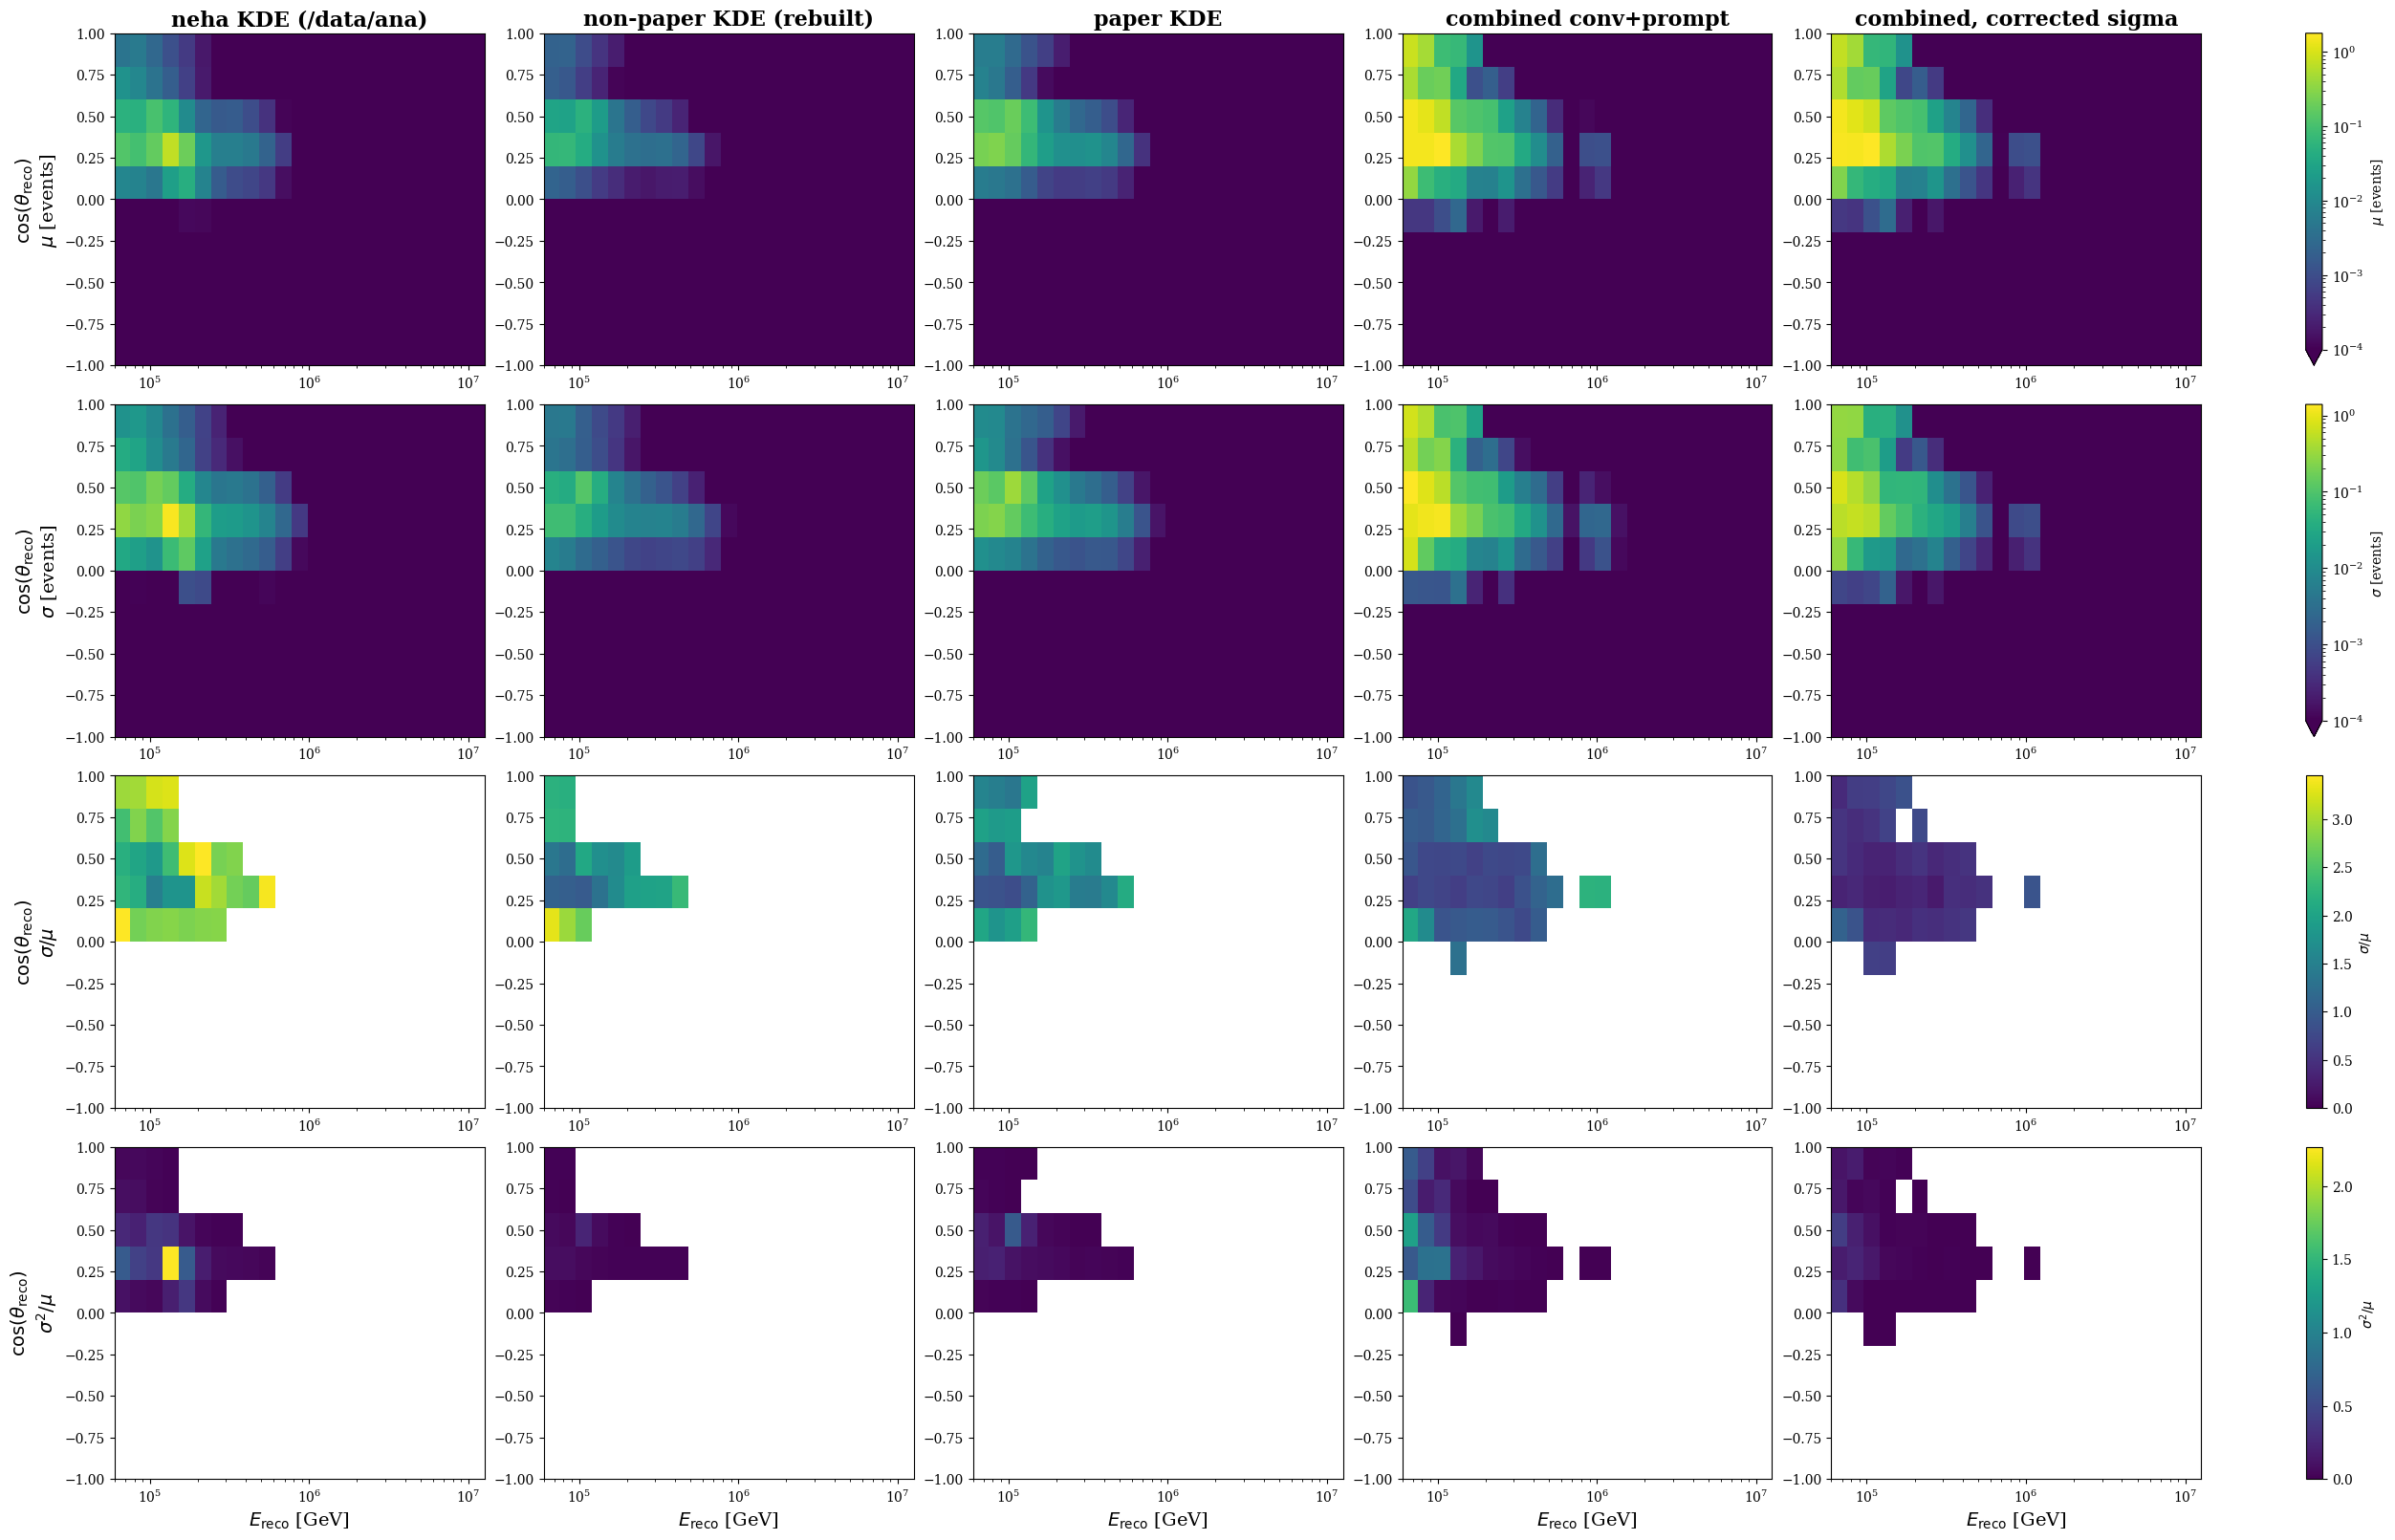

In [6]:
# 2D maps: mu, sigma, sigma/mu and ssq/mu, one row per quantity with a shared colour scale
quantities = {}
for name in labels:
    with np.errstate(divide="ignore", invalid="ignore"):
        quantities[name] = {
            r"$\mu$ [events]": mu[name],
            r"$\sigma$ [events]": sigma[name],
            r"$\sigma / \mu$": np.where(mu[name] > 1e-3, sigma[name] / mu[name], np.nan),
            r"$\sigma^2 / \mu$": np.where(mu[name] > 1e-3, sigma[name]**2 / mu[name], np.nan),
        }
rows = list(quantities["combined"])

fig, axes = plt.subplots(len(rows), len(labels), figsize=(5 * len(labels), 4 * len(rows)), constrained_layout=True)
for i, row in enumerate(rows):
    values = [to_2d(quantities[name][row]) for name in labels]
    log_scale = row.endswith("[events]")
    # the KDE tails run down to 1e-60 events, so the rate maps are clipped at 1e-4 events
    # (everything below is irrelevant for the fit) instead of spanning the full range
    norm = mcolors.LogNorm(vmin=1e-4, vmax=np.nanmax([np.nanmax(v) for v in values])) if log_scale else None
    vmin, vmax = (None, None) if log_scale else (0, np.nanmax([np.nanmax(v) for v in values]))
    for j, name in enumerate(labels):
        ax = axes[i, j]
        h = np.where(values[j] > 0, values[j], np.nan) if log_scale else values[j]
        mesh = ax.pcolormesh(energy_bins, zenith_bins, h.T, norm=norm, vmin=vmin, vmax=vmax, cmap="viridis")
        ax.set_xscale("log")
        if i == 0:
            ax.set_title(labels[name], fontdict={**font_title, "size": 16})
        if i == len(rows) - 1:
            ax.set_xlabel(TRACKS_SPEC["dim_info"]["reco_energy"]["x_label"], fontdict={**font_axis_label, "size": 14})
        if j == 0:
            ax.set_ylabel(r"$\cos(\theta_{\mathrm{reco}})$" + "\n" + row, fontdict={**font_axis_label, "size": 14})
        # the ratio rows are only defined where there is an expectation
    fig.colorbar(mesh, ax=axes[i, :], label=row, extend="min" if log_scale else "neither")
plt.savefig(f"{plotting_path}/template_maps.png", bbox_inches="tight")
plt.show()

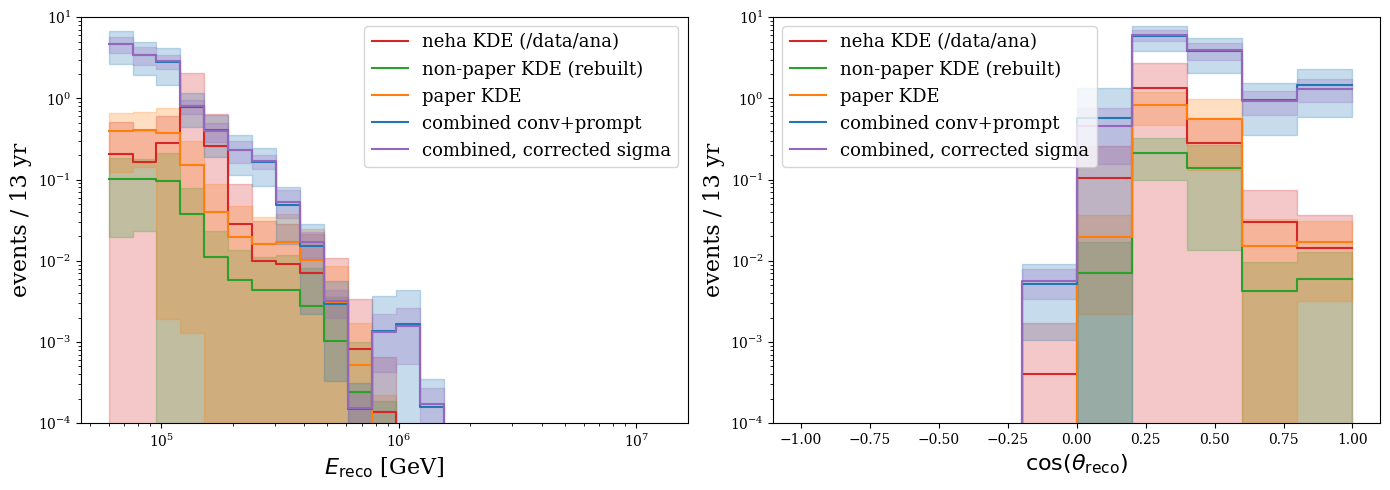

In [7]:
# 1D projections of the expectation with a +- sigma band (sigma added in quadrature along the summed axis)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in labels:
    mu_2d, sigma_2d = to_2d(mu[name]), to_2d(sigma[name])
    for ax, axis, bins, xlabel, log_x in [
        (axes[0], 1, energy_bins, TRACKS_SPEC["dim_info"]["reco_energy"]["x_label"], True),
        (axes[1], 0, zenith_bins, r"$\cos(\theta_{\mathrm{reco}})$", False),
    ]:
        y = mu_2d.sum(axis=axis)
        yerr = np.sqrt((sigma_2d**2).sum(axis=axis))
        centers = np.repeat(bins, 2)[1:-1]
        ax.plot(centers, np.repeat(y, 2), color=colours[name], label=labels[name])
        ax.fill_between(centers, np.repeat(y - yerr, 2), np.repeat(y + yerr, 2), color=colours[name], alpha=0.25)
        ax.set_xlabel(xlabel, fontdict={**font_axis_label, "size": 16})
        if log_x:
            ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_ylim(1e-4, 1e1)
for ax in axes:
    ax.set_ylabel("events / 13 yr", fontdict={**font_axis_label, "size": 16})
    ax.legend(prop=font_legend)
plt.tight_layout()
plt.savefig(f"{plotting_path}/template_projections.png", bbox_inches="tight")
plt.show()

## Per-bin MC variance in HESE Tracks
How much of the total `ssq` the muon template is responsible for, from the per-component histograms of the step2
best-fit graph (`../graphs/nbestfit50_all_param_2sigma_1D_10steps_PassingHESE/`). Each file holds
`histograms[det_conf]` ($\mu$) and `fluctuations[det_conf]` ($\sigma^2$, written by `make_histogram.py` from
`NNMFitter.get_asimov_fluctuations`). For event-based components `ssq` is $\sum w^2$ of the MC events in the bin;
the template components add $(\mathtt{template\_fluctuation} \cdot \mathrm{livetime})^2$.

This graph was fitted with the first combined template, but both template generations can be read off it without a
new histogram. For a template component NNMFit writes $\mu = N(1 \pm a)\,T \cdot \mathrm{livetime}$ and
$\sigma^2 = (N(1 \pm a)\,f \cdot \mathrm{livetime})^2$, so $\sigma^2/\mu^2 = (f/T)^2$ per bin, independent of the
fitted norm and asymmetry. Rescaling each muon component by the relative error $f/T$ of its own template pickle is
therefore exact, and the cell below asserts that it reproduces the stored `fluctuations` for the template the fit
actually used before applying it to the corrected one. Only `ssq` is swapped: $\mu$ stays as fitted, which is right
to better than the 0.53 $\sigma$ by which the reseeded bootstrap moved the central template.

In [13]:
graphs_path = f"{STEP2_DIR}/graphs/nbestfit50_all_param_2sigma_1D_10steps_PassingHESE"

def load_component(filename):
    """mu and ssq of one component in HESE Tracks."""
    d = pickle.load(open(f"{graphs_path}/{filename}", "rb"))
    fluctuations = d["fluctuations"] or {}
    return d["histograms"][DET_CONF], fluctuations.get(DET_CONF)

mu_tot, ssq_tot = load_component("MC_Histogram_nosyst.pickle")
components = {
    "astro":       load_component("MC_Histogram_Astro_nosyst.pickle"),
    "conv":        load_component("MC_Histogram_Conv_nosyst.pickle"),
    "prompt":      load_component("MC_Histogram_Prompt_nosyst.pickle"),
    "muon conv":   load_component("MC_Histogram_MuonConv_nosyst.pickle"),
    "muon prompt": load_component("MC_Histogram_MuonPrompt_nosyst.pickle"),
}
mu_muon = components["muon conv"][0] + components["muon prompt"][0]
ssq_muon = components["muon conv"][1] + components["muon prompt"][1]

# ssq of the muon components for either template generation, by rescaling with f / T per bin (see above).
# combined_pairs maps a generation to its (conv, prompt) template keys, so position 0/1 picks the right one.
muon_template_position = {"muon conv": 0, "muon prompt": 1}

def relative_template_error(key):
    """f / T per bin of one template pickle, 0 where the template is empty."""
    template, fluctuation = raw[key]["template"], raw[key]["template_fluctuation"]
    return np.where(template > 0, fluctuation / np.where(template > 0, template, 1.0), 0.0)

ssq_components, ssq_muon_gen, ssq_tot_gen = {}, {}, {}
for gen, pair in combined_pairs.items():
    ssq_components[gen] = {
        comp: (m * relative_template_error(pair[muon_template_position[comp]]))**2
        if comp in muon_template_position else s
        for comp, (m, s) in components.items()
    }
    ssq_muon_gen[gen] = ssq_components[gen]["muon conv"] + ssq_components[gen]["muon prompt"]
    ssq_tot_gen[gen] = ssq_tot - ssq_muon + ssq_muon_gen[gen]

# the generation the graph was fitted with must come back exactly
np.testing.assert_allclose(ssq_muon_gen["combined"], ssq_muon, rtol=1e-10)

tag = {"combined": "combined", "combined_sigma": "corrected"}
df_components = pd.DataFrame({
    comp: {"mu [events]": m.sum(), "mu [%]": 100 * m.sum() / mu_tot.sum(),
           **{f"ssq ({tag[gen]})": ssq_components[gen][comp].sum() for gen in combined_pairs},
           **{f"ssq [%] ({tag[gen]})": 100 * ssq_components[gen][comp].sum() / ssq_tot_gen[gen].sum()
              for gen in combined_pairs}}
    for comp, (m, s) in components.items()
})
df_components["total"] = {"mu [events]": mu_tot.sum(), "mu [%]": 100.0,
                          **{f"ssq ({tag[gen]})": ssq_tot_gen[gen].sum() for gen in combined_pairs},
                          **{f"ssq [%] ({tag[gen]})": 100.0 for gen in combined_pairs}}
with pd.option_context("display.float_format", "{:.4g}".format, "display.width", 200):
    display(df_components)

,astro,conv,prompt,muon conv,muon prompt,total
mu [events],18.71,9.422,0.1342,3.74,2.682,34.68
mu [%],53.93,27.16,0.3869,10.78,7.734,100
ssq (combined),0.01488,0.036,2.724e-06,2.202,0.4161,2.701
ssq (corrected),0.01488,0.036,2.724e-06,0.566,0.1123,0.7608
ssq [%] (combined),0.551,1.333,0.0001009,81.54,15.41,100
ssq [%] (corrected),1.956,4.732,0.0003581,74.39,14.76,100


In [14]:
# the effective weight ssq/mu SAY sees, with either muon template and with none
filled = mu_tot > 0.05
print(f"ssq/mu over the {filled.sum()} Tracks bins with mu > 0.05:")
for gen in combined_pairs:
    w = ssq_tot_gen[gen][filled] / mu_tot[filled]
    print(f"   with the {labels[gen]:<25} template: median {np.median(w):.4f}  mean {w.mean():.4f}  max {w.max():.4f}")
w_without = (ssq_tot - ssq_muon)[filled] / mu_tot[filled]
print(f"   without {'the muon template':<31}: median {np.median(w_without):.4f}  mean {w_without.mean():.4f}  "
      f"max {w_without.max():.4f}")

# the 15 bins with the largest expectation, for both template generations
order = np.argsort(mu_tot)[::-1][:15]
df_bins = pd.DataFrame({
    "bin": order,
    "mu_tot": mu_tot[order],
    "mu_muon": mu_muon[order],
    "f_mu_muon": mu_muon[order] / mu_tot[order],
    **{f"{column} ({tag[gen]})": values for gen in combined_pairs for column, values in {
        "ssq_tot": ssq_tot_gen[gen][order],
        "ssq_muon": ssq_muon_gen[gen][order],
        "f_ssq_muon": ssq_muon_gen[gen][order] / ssq_tot_gen[gen][order],
        "ssq/mu": ssq_tot_gen[gen][order] / mu_tot[order],
    }.items()},
}).set_index("bin")
with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 250, "display.max_columns", 25):
    display(df_bins)

ssq/mu over the 88 Tracks bins with mu > 0.05:
   with the combined conv+prompt      template: median 0.0021  mean 0.0293  max 0.5442
   with the combined, corrected sigma template: median 0.0017  mean 0.0087  max 0.1553
   without the muon template              : median 0.0008  mean 0.0015  max 0.0103


,mu_tot,mu_muon,f_mu_muon,ssq_tot (combined),ssq_muon (combined),f_ssq_muon (combined),ssq/mu (combined),ssq_tot (corrected),ssq_muon (corrected),f_ssq_muon (corrected),ssq/mu (corrected)
bin,,,,,,,,,,,
4,1.531,0.210,0.137,0.207,0.198,0.952,0.135,0.072,0.062,0.863,0.047
5,1.471,0.000,0.000,0.015,0.000,0.000,0.010,0.015,0.000,0.000,0.010
23,1.358,0.943,0.694,0.506,0.506,0.999,0.373,0.087,0.086,0.997,0.064
13,1.317,0.819,0.622,0.431,0.431,0.999,0.327,0.120,0.119,0.996,0.091
3,1.224,0.789,0.644,0.298,0.298,0.998,0.244,0.079,0.078,0.994,0.064
2,1.126,0.779,0.692,0.613,0.612,1.000,0.544,0.175,0.175,0.998,0.155
14,1.108,0.045,0.041,0.012,0.006,0.549,0.010,0.007,0.002,0.285,0.007
15,1.092,0.000,0.000,0.007,0.000,0.000,0.006,0.007,0.000,0.000,0.006
24,0.980,0.022,0.023,0.004,0.000,0.095,0.004,0.004,0.000,0.021,0.004


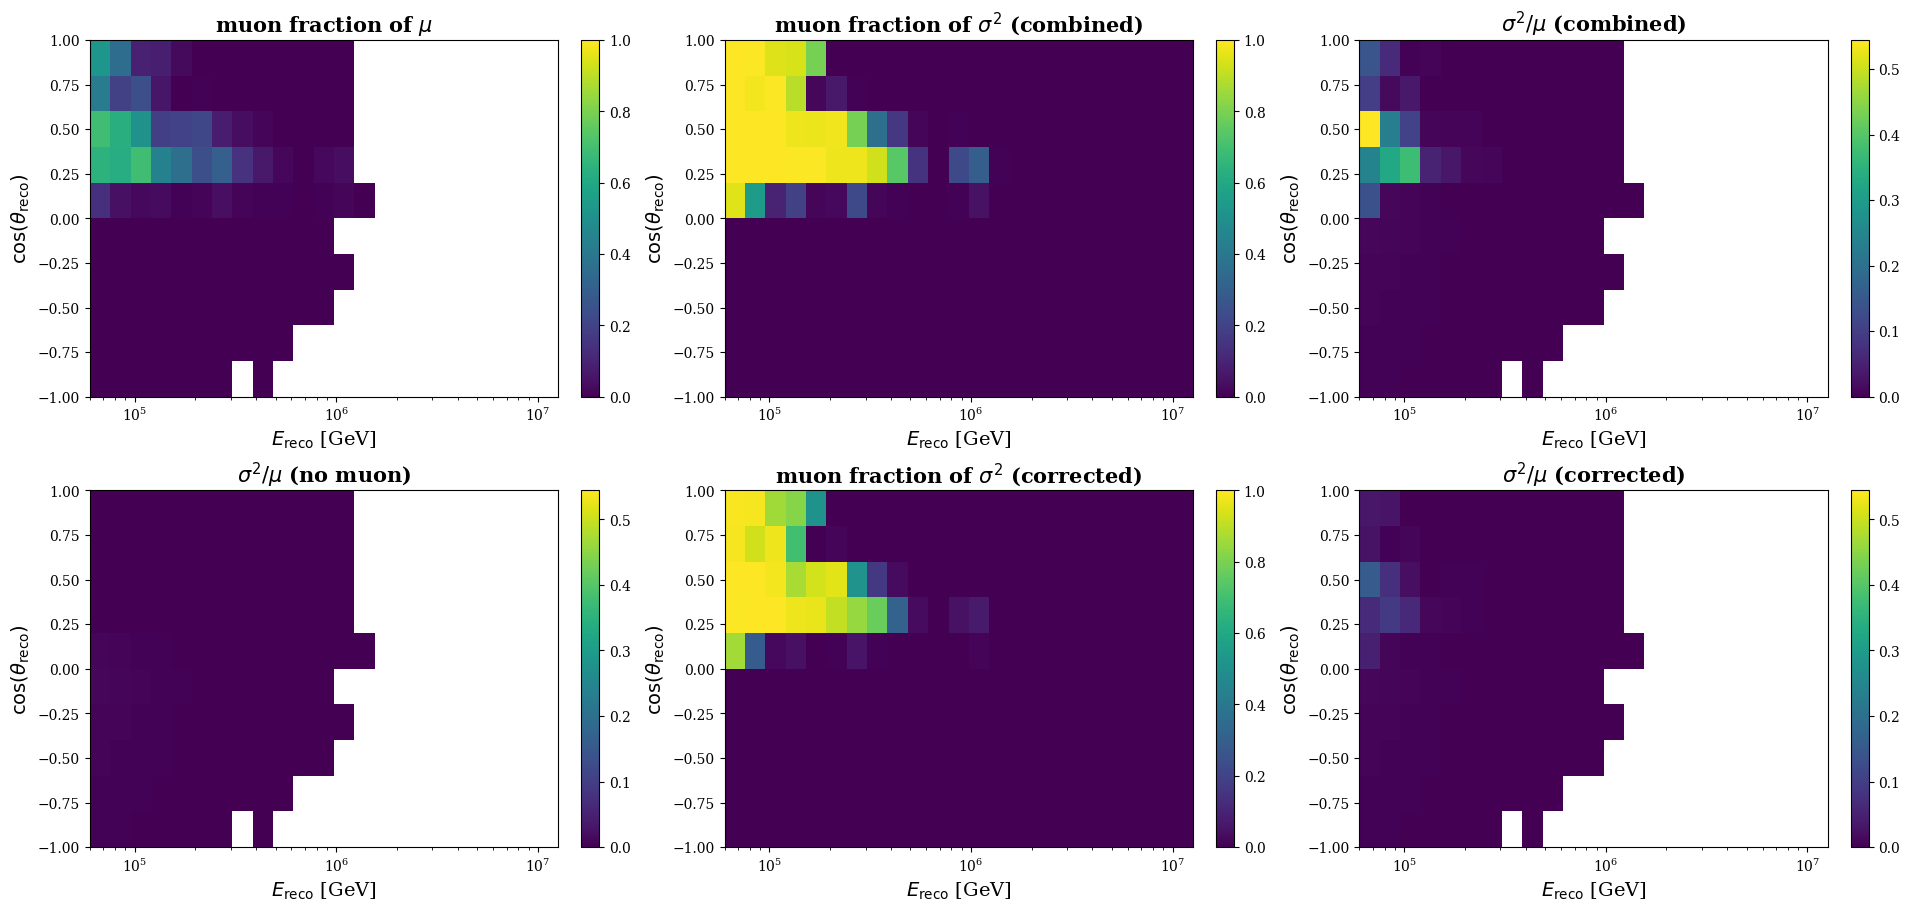

In [15]:
# maps of the muon fraction of mu and of ssq, and of ssq/mu with and without the muon component.
# Left column: the two maps that do not depend on the template. Right two columns: the first combined
# template (top) against the corrected one (bottom), on the same colour scale.
with np.errstate(divide="ignore", invalid="ignore"):
    maps = {
        r"muon fraction of $\mu$":                 np.where(mu_tot > 0.01, mu_muon / mu_tot, np.nan),
        r"muon fraction of $\sigma^2$ (combined)": np.where(ssq_tot_gen["combined"] > 0,
                                                            ssq_muon_gen["combined"] / ssq_tot_gen["combined"], np.nan),
        r"$\sigma^2/\mu$ (combined)":              np.where(mu_tot > 0.01, ssq_tot_gen["combined"] / mu_tot, np.nan),
        r"$\sigma^2/\mu$ (no muon)":               np.where(mu_tot > 0.01, (ssq_tot - ssq_muon) / mu_tot, np.nan),
        r"muon fraction of $\sigma^2$ (corrected)": np.where(ssq_tot_gen["combined_sigma"] > 0,
                                                             ssq_muon_gen["combined_sigma"] / ssq_tot_gen["combined_sigma"], np.nan),
        r"$\sigma^2/\mu$ (corrected)":             np.where(mu_tot > 0.01, ssq_tot_gen["combined_sigma"] / mu_tot, np.nan),
    }
fig, axes = plt.subplots(2, 3, figsize=(19, 9), constrained_layout=True)
vmax_w = np.nanmax(maps[r"$\sigma^2/\mu$ (combined)"])
for ax, (title, values) in zip(axes.ravel(), maps.items()):
    vmax = 1.0 if "fraction" in title else vmax_w
    mesh = ax.pcolormesh(energy_bins, zenith_bins, to_2d(values).T, vmin=0, vmax=vmax, cmap="viridis")
    ax.set_xscale("log")
    ax.set_title(title, fontdict={**font_title, "size": 15})
    ax.set_xlabel(TRACKS_SPEC["dim_info"]["reco_energy"]["x_label"], fontdict={**font_axis_label, "size": 14})
    ax.set_ylabel(r"$\cos(\theta_{\mathrm{reco}})$", fontdict={**font_axis_label, "size": 14})
    fig.colorbar(mesh, ax=ax)
plt.savefig(f"{plotting_path}/tracks_ssq_maps.png", bbox_inches="tight")
plt.show()

**Outcome:** the muon template is 19% of the HESE Tracks expectation but **97% of the total $\sigma^2$** with the template the fit used, and still 89% with the corrected one. Without it,
$\sigma^2/\mu$ is at most 0.01 per bin, i.e. SAY is indistinguishable from Poisson for every other component (the
neutrino MC has many more, much lighter-weighted events). With it, $\sigma^2/\mu$ reaches 0.54 and $\sigma/\mu$ 0.70,
and those are exactly the down-going bins ($\cos\theta \approx 0.2 - 0.6$, $E_{\mathrm{reco}} \lesssim 200$ TeV) where
the muon template dominates the expectation. Whatever SAY does differently from Poisson in this analysis, it does
because of the muon template.

Correcting the template error does not change that picture, it moves it along: $\sum\sigma^2$ over the Tracks bins
falls 2.70 $\to$ 0.76 events$^2$, the muon share 97% $\to$ 89%, the largest $\sigma^2/\mu$ 0.54 $\to$ 0.16 and the
largest $\sigma/\mu$ 0.70 $\to$ 0.37, and one bin instead of eight is left above $\sigma^2/\mu$ = 0.1. The mean
$\sigma^2/\mu$ over the 88 filled bins goes 0.029 $\to$ 0.0087 against a no-muon floor of 0.0015, i.e. three
quarters of the way from the first combined template to a fit in which SAY and Poisson would be the same
likelihood; the event-weighted $1/(1+\sigma^2/\mu^2)$ printed below moves 0.939 $\to$ 0.978 with 0.9955 as the
floor. That is the same ~3x as everywhere else in this notebook, and the same reason the residual closure bias is
−0.10 and not 0.

These histograms are the *data* best fit, where `combined_muongun_norm` ≈ 0.5, not the Asimov injection at norm 1,
where the muon $\sigma^2$ is ~4x larger because `ssq` of a template scales as $N^2$. The non-muon $\sigma^2$ is two
orders of magnitude smaller either way, so the 97% conclusion does not depend on that. For exact Asimov numbers, run
`NNMFit/scripts/make_histogram.py` with a scan's `Fit_Configuration.yaml`, which dumps `histograms` and
`fluctuations` of the Asimov set directly; it loads the full datasets, so that belongs in a batch job.

## Why SAY shrinks the muon norm
Take one bin, Asimov data $k = \mu_0$, and a norm $N$ scaling a component with rate $m_0$ and fluctuation $s_0$.
SAY has $\mu = N m_0$ and $\sigma^2 = N^2 s_0^2$, so

$$\alpha = \frac{\mu^2}{\sigma^2} + 1 = \frac{m_0^2}{s_0^2} + 1, \qquad \beta = \frac{\mu}{\sigma^2} = \frac{m_0}{N s_0^2},$$

i.e. $\alpha$ does not depend on $N$ and only $\beta$ does. The $N$-dependent part of the log-likelihood
(`SAYLLH.compute_log_L`) is $\alpha \log\beta - (k+\alpha)\log(1+\beta)$, which is stationary at $\beta^* = \alpha / k$.
With $k = m_0$ that gives

$$N^* = \frac{k\, m_0}{m_0^2 + s_0^2} = \frac{1}{1 + (s_0/m_0)^2} \;<\; 1 .$$

So SAY always shrinks a component with a large relative fluctuation, and the other norms absorb the events that
disappear — here `astro_norm` rises as the muon norm falls. Two things decide how far the muon norm actually moves:

- **where** it is pulled to, $N^*$, set by the *relative* $\sigma/\mu$ of the template. All the KDEs have
  $\sigma/\mu \sim 1$ per bin, so all of them have a similar $N^* \approx 0.3 - 0.6$;
- **how hard** it is pulled, i.e. the curvature of the likelihood in the muon norm against the Gaussian prior on it
  (`prior: 1.0`, `prior_width: 0.5` in `configs/flavor_globalfit/parameters.yaml`). That curvature scales with the
  *absolute* number of muon events, so a template holding 0.37 events cannot argue with the prior, while one holding
  12.6 events gets most of the way to $N^*$.

The toy fit below separates the two.

In [11]:
def say_log_l(k, mu, ssq):
    # numpy transcription of NNMFit SAYLLH.compute_log_L (likelihoods/say_llh.py)
    ssq = np.clip(ssq, 0, mu**2)
    safe_mu, safe_ssq = np.where(mu > 0, mu, 1.0), np.where(ssq > 0, ssq, 1.0)
    poisson = k * np.log(safe_mu) - mu - gammaln(k + 1)
    alpha = mu * mu / safe_ssq + 1.0
    beta = mu / safe_ssq
    llh_eff = (alpha * np.log(beta) + gammaln(k + alpha) - gammaln(k + 1)
               - (k + alpha) * np.log1p(beta) - gammaln(alpha))
    llh_eff = np.where(ssq > 0, llh_eff, poisson)
    return np.where(mu > 0, llh_eff, np.where(k > 0, -690.0 * k, 0.0))

# toy SAY fit of (astro norm, muon norm) over the 230 Tracks bins:
#   mu   = N_astro * astro + (conv + prompt) + N_muon * template
#   ssq  = N_astro^2 * ssq_astro + (ssq_conv + ssq_prompt) + N_muon^2 * sigma_template^2
# Asimov data is the expectation at (1, 1). gamma_astro, conv_norm and the cascade/double-cascade
# channels are frozen, so this is not the full fit, only the degeneracy that drives the bias.
ASTRO_NORM_INJECTED = 2.1233  # analysis_configs/asimov/SAY/hese/hese_HESEBestfit_SPL.yaml
PRIOR_WIDTH = 0.5             # parameters.yaml, prior 1.0 on the muon norm

mu_astro, ssq_astro = components["astro"]
mu_nu = components["conv"][0] + components["prompt"][0]
ssq_nu = components["conv"][1] + components["prompt"][1]

def toy_fit(mu_template, sigma_template, use_prior=True):
    def expectation(params):
        n_astro, n_muon = params
        return (n_astro * mu_astro + mu_nu + n_muon * mu_template,
                n_astro**2 * ssq_astro + ssq_nu + n_muon**2 * sigma_template**2)
    k_asimov = expectation([1.0, 1.0])[0]

    def neg_llh(params):
        value = -2 * np.sum(say_log_l(k_asimov, *expectation(params)))
        return value + (((params[1] - 1.0) / PRIOR_WIDTH)**2 if use_prior else 0.0)

    result = minimize(neg_llh, [1.0, 1.0], method="L-BFGS-B", bounds=[(1e-3, 5), (1e-6, 5)])
    return result.x

toy, rows = {}, {}
for name in labels:
    for use_prior in [True, False]:
        n_astro, n_muon = toy_fit(mu[name], sigma[name], use_prior=use_prior)
        toy[(name, use_prior)] = (n_astro, n_muon)
        key = (labels[name], "with prior" if use_prior else "no prior")
        rows[key] = {"toy astro_norm - injected": ASTRO_NORM_INJECTED * (n_astro - 1),
                     "toy muon norm - 1": n_muon - 1,
                     "scan astro_norm - injected": closure_bias.loc[name, "astro_norm - injected"],
                     "scan muon norm - 1": closure_bias.loc[name, "muon norm - 1"]}
df_toy = pd.DataFrame(rows).T
with pd.option_context("display.float_format", "{:+.4f}".format):
    display(df_toy)

toy astro_norm - injected  \
neha KDE (/data/ana)      with prior                    -0.0056   
                          no prior                      +0.0987   
non-paper KDE (rebuilt)   with prior                    -0.0094   
                          no prior                      +0.0216   
paper KDE                 with prior                    +0.0063   
                          no prior                      +0.0829   
combined conv+prompt      with prior                    +0.1879   
                          no prior                      +0.2645   
combined, corrected sigma with prior                    +0.0567   
                          no prior                      +0.0911   

                                      toy muon norm - 1  \
neha KDE (/data/ana)      with prior            -0.2308   
                          no prior              -0.7007   
non-paper KDE (rebuilt)   with prior            -0.0159   
                          no prior              -0.6717   
paper KDE                 with prior            -0.1106   
                          no prior              -0.5782   
combined conv+prompt      with prior            -0.3091   
                          no prior              -0.3998   
combined, corrected sigma with prior            -0.1043   
                          no prior              -0.1523   

                                      scan astro_norm - injected  \
neha KDE (/data/ana)      with prior                         NaN   
                          no prior                           NaN   
non-paper KDE (rebuilt)   with prior                     +0.0007   
                          no prior                       +0.0007   
paper KDE                 with prior                     +0.0361   
                          no prior                       +0.0361   
combined conv+prompt      with prior                     +0.3035   
                          no prior                       +0.3035   
combined, corrected sigma with prior                     +0.0804   
                          no prior                       +0.0804   

                                      scan muon norm - 1  
neha KDE (/data/ana)      with prior                 NaN  
                          no prior                   NaN  
non-paper KDE (rebuilt)   with prior             -0.0220  
                          no prior               -0.0220  
paper KDE                 with prior             -0.1349  
                          no prior               -0.1349  
combined conv+prompt      with prior             -0.3026  
                          no prior               -0.3026  
combined, corrected sigma with prior             -0.1004  
                          no prior               -0.1004

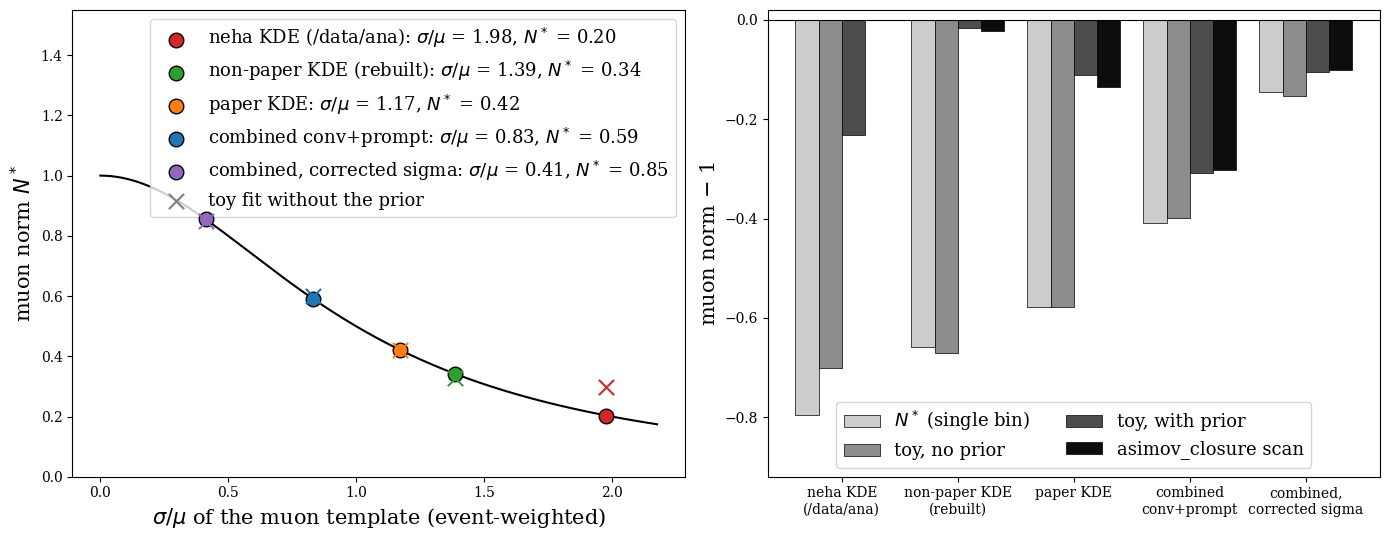

event-weighted 1/(1+sigma^2/mu^2) over the Tracks bins, with muon ssq: 0.9390
event-weighted 1/(1+sigma^2/mu^2) over the Tracks bins, without muon ssq: 0.9955


In [12]:
# left: the single-bin result N* = 1/(1+(sigma/mu)^2) against the event-weighted per-bin sigma/mu of each template,
#       with the muon norm the toy finds without the prior, which that formula should predict
# right: how far the muon norm actually moves once the prior is there
rel_eff, n_star = {}, {}
for name in labels:
    with np.errstate(divide="ignore", invalid="ignore"):
        rel = np.where(mu[name] > 1e-3, sigma[name] / mu[name], np.nan)
    weights = np.where(np.isfinite(rel), mu[name], 0.0)
    rel_eff[name] = np.sum(weights * np.nan_to_num(rel)) / weights.sum()
    n_star[name] = 1 / (1 + rel_eff[name]**2)

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 5.5))

rel_axis = np.linspace(0, 1.1 * max(rel_eff.values()), 200)
ax_left.plot(rel_axis, 1 / (1 + rel_axis**2), color="k", lw=1.5)
for name in labels:
    ax_left.scatter([rel_eff[name]], [n_star[name]], s=110, color=colours[name], edgecolor="k", zorder=10,
                    label=f"{labels[name]}: $\\sigma/\\mu$ = {rel_eff[name]:.2f}, $N^*$ = {n_star[name]:.2f}")
    ax_left.scatter([rel_eff[name]], [toy[(name, False)][1]], s=120, marker="x", color=colours[name], zorder=11)
ax_left.scatter([], [], s=120, marker="x", color="grey", label="toy fit without the prior")
ax_left.set_xlabel(r"$\sigma / \mu$ of the muon template (event-weighted)", fontdict={**font_axis_label, "size": 15})
ax_left.set_ylabel(r"muon norm $N^*$", fontdict={**font_axis_label, "size": 15})
ax_left.set_ylim(0, 1.55)  # headroom for the legend: five points now span the whole curve
ax_left.legend(prop=font_legend, loc="upper right")

width = 0.2
series_offsets = {"$N^*$ (single bin)": -1.5, "toy, no prior": -0.5, "toy, with prior": 0.5, "asimov_closure scan": 1.5}
series_values = {
    "$N^*$ (single bin)":  [n_star[name] - 1 for name in labels],
    "toy, no prior":       [toy[(name, False)][1] - 1 for name in labels],
    "toy, with prior":     [toy[(name, True)][1] - 1 for name in labels],
    "asimov_closure scan": [closure_bias.loc[name, "muon norm - 1"] for name in labels],
}
x = np.arange(len(labels))
for (series, offset), greyscale in zip(series_offsets.items(), ["0.8", "0.55", "0.3", "0.05"]):
    ax_right.bar(x + offset * width, series_values[series], width, label=series,
                 color=greyscale, edgecolor="k", lw=0.5)
ax_right.set_xticks(x)
ax_right.set_xticklabels([textwrap.fill(labels[name], 17) for name in labels], fontsize=10)
ax_right.set_ylabel("muon norm $-$ 1", fontdict={**font_axis_label, "size": 15})
ax_right.axhline(0, color="k", lw=0.8)
ax_right.set_ylim(-0.92, 0.02)
ax_right.legend(prop=font_legend, loc="lower center", ncol=2)

plt.tight_layout()
plt.savefig(f"{plotting_path}/say_norm_bias.png", bbox_inches="tight")
plt.show()

# the same single-bin factor applied to the Tracks expectation as a whole (a norm scaling every component)
mask = mu_tot > 1e-3
for name, ssq in [("with muon ssq", ssq_tot_gen["combined"]),
                  ("with corrected muon ssq", ssq_tot_gen["combined_sigma"]),
                  ("without muon ssq", ssq_tot - ssq_muon)]:
    pull = 1 / (1 + ssq[mask] / mu_tot[mask]**2)
    print(f"event-weighted 1/(1+sigma^2/mu^2) over the Tracks bins, {name}: "
          f"{np.sum(mu_tot[mask] * pull) / mu_tot[mask].sum():.4f}")

**Outcome:** the toy reproduces the muon-norm pull of the real scans closely — −0.31 against −0.303 for the combined
template, −0.11 against −0.135 for the paper KDE and −0.016 against −0.022 for the non-paper KDE — from nothing but
the template $\sigma$, the Tracks expectation and the muon prior. The `astro_norm` pull comes out with the right sign
and order but too small (+0.19 against +0.304 for the combined template), as expected: the toy freezes
`gamma_astro`, `conv_norm` and the cascade and double-cascade channels, which in the real fit give further freedom to
absorb the missing muon events.

The two panels separate the two effects above. **Left:** without the prior the toy lands on or near the single-bin
$N^* = 1/(1+(\sigma/\mu)^2)$ (crosses close to the curve; the `/data/ana` template sits above it, at 0.30 against
0.20, because `ssq` is clipped to $\mu^2$ in more than half of its bins), and the templates with the *fewest* events
would be pulled furthest: 0.30 for the `/data/ana` KDE and 0.33 for the non-paper one, against 0.60 for the combined
template, because their per-bin $\sigma/\mu$ is the largest. The relative uncertainty alone therefore does not explain the
ordering of the closure bias — it predicts the opposite one. **Right:** with the prior the ordering flips. The
non-paper and paper templates hold 0.37 and 1.44 events, far too little weight to argue with a prior of width 0.5, so
they stay near 1 (−0.016, −0.11) — but the `/data/ana` template holds 1.77 events with $\sum\sigma^2$ = 2.03 and
already reaches −0.23. The combined template holds 12.6 events and gets most of the way to its $N^*$
(−0.31 of a possible −0.41).

That is the answer to the closure problem: **it is the absolute size of the muon template, not its relative
uncertainty, that broke SAY closure.** The per-bin relative error of the KDE is of order 1 for all three templates;
raising the normalisation by a factor 9 raised $\sum\sigma^2$ by a factor ~300 and with it the weight SAY puts on
shrinking the muon norm.

It also follows that the earlier templates were never unbiased, only prior-dominated: their pull was small because
the muon template had no statistical power, not because SAY was doing the right thing.

**Confirmed since.** The templates were rebuilt with the corrected 1 sigma error
(`FlavorGlobalFit/muon_template_hese`, the `_sigma` folders), giving $\sum\sigma^2$ = 2.18 events$^2$, and the Asimov
closure scan was repeated as `SAY_newmuon` in `asimov_closure.ipynb`. That template is the fifth column everywhere
above, `combined, corrected sigma`: its $N^*$ is 0.85 instead of 0.59, the toy gives a muon-norm pull of −0.104 and
the real scan **−0.100**, with `astro_norm` +0.080 against +0.304 before. Dividing the template $\sigma$ by 2 moved
the pull by a factor 3 and nothing else about the template changed, which is as direct a demonstration as this
notebook can give that the muon $\sigma$, not the muon rate on its own, is what SAY reacts to.

## What changed in the templates
**Normalisation**, the change that broke closure:

| template | weights | scaling | events / 13 yr |
|---|---|---|---|
| neha KDE (`/data/ana/.../MuonGun/Tracks_KDE.pickle`) | not recorded in the pickle | not recorded | 1.77 |
| non-paper KDE (`hese_muons_kde.ipynb`) | `MuonWeight`, v7-v1 track sample, 19 MC events above 60 TeV | none | 0.37 |
| paper KDE (`hese_muons_paper.ipynb`) | `MuonWeight` / 2.1 | x 8.23 (tagged-muon rate of the HESE 7.5 yr paper x 2.1 geometry) | 1.44 |
| combined (`FlavorGlobalFit/muon_template_hese/`) | `MuonWeightCombinedConv` and `MuonWeightCombinedPrompt`, v8-v2 `ExtraMuon` sample | x 9.66 / x 1.05, each chosen to give 6.3 events, half of the expected 12.6 | 12.60 |

The muon rate is ~9x the paper template and ~34x the non-paper one. Whether 12.6 events is the right expectation is a
separate question from the closure; the point here is that $\sigma^2$ scales as the square of the normalisation while
the per-bin relative uncertainty of the KDE stayed of order 1, so the absolute $\sigma^2$ SAY sees grew by ~300.

**KDE settings** that also changed (visible in the maps above as a sharper horizon edge in the combined template):
`bw_method = lambda k: 0.6 * k.silverman_factor()` instead of plain `silverman`, and mirroring at the 60 TeV cut and
at $\cos\theta = 1$ (`bounds=((4.778, None), (None, 1.0))`, `thresholds=((4.5, None), (None, 1.3))`) instead of
`bounds=((4.5, 7.1), (-1.1, 1.2))`, `thresholds=((4.778, 7), (-1, 1.1))`. The new notebook also renormalises the
integrated KDE back to the weight sum (`kde_norm`), which the old ones had commented out.

**Follow-ups**

- `template_fluctuation` is stored as `up - low`, i.e. **2x the bootstrap std**, summed linearly over the fine KDE
  grid inside each analysis bin (`FlavorGlobalFit/muon_template_hese/kde_utils.py`,
  `integrate_kde_to_analysis_bins`; the same code in `notebooks/muons/hese_muons_paper.ipynb` and
  `hese_muons_kde.ipynb`). `KDEKernel.func_rate_density` returns `(mean, std)` for a bootstrap kernel
  (`NNMFit/kde_tools/kde_utilities.py`), and NNMFit squares the stored value as a $\sigma$
  (`core/histogram_builder.py`), so the $\sigma^2$ entering SAY is ~4x too large. All three templates share this, so
  it is not what changed, but it is the cheapest factor to recover: dividing `template_fluctuation` by 2 divides the
  muon `ssq` by 4. **Done:** `kde_utils.integrate_kde_to_analysis_bins` now stores `(up - low) / 2` and the templates
  were rebuilt into the `_sigma` folders with a seeded bootstrap; they are the `combined, corrected sigma` column
  above. See the README there and the `_newmuon` scans in `asimov_closure.ipynb`.
- `IC86_pass2_SnowStorm_FTP_HESE_Combined.cfg` lists `muontemplate_hese` and `muontemplate_prompt_hese` in
  `excluded_components` but not `muontemplate_combined_hese`. Harmless for these fits, whose detector configs are
  Cascades, DoubleCascades and Tracks, but inconsistent with the other two HESE configs.